# 02c · Tendencias exploratorias en América Latina

**Pregunta:** *Entre 2006 y 2025, mientras bajaban la fecundidad y la mortalidad infantil en América Latina, ¿se redujo o creció la desigualdad de aprendizaje dentro de los países?*

Primer vistazo a los datos preparados en `02b_america_latina`. Es **exploratorio**: gráficos rápidos para ver patrones y una primera revisión de robustez. Los gráficos finales, en inglés y pulidos, van en `03_visualizaciones`.

Recordatorios para leer los resultados:

- Son **8 países**: los números describen, no prueban. Cualquier correlación con n = 8 es frágil.
- Que dos cosas cambien al mismo tiempo **no implica que una cause la otra**.
- 2025 es **proyección** en la base de la ONU; 2022 está afectado por la pandemia.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

from src.utils import cargar_processed
from src.estilo import aplicar_estilo, PALETA, DESTACADO, GRIS

aplicar_estilo()
pd.set_option("display.max_columns", None)

al = cargar_processed("al_wpp_1950_2100.csv")
panel = cargar_processed("al_panel_pisa.csv")
ULTIMO_ESTIMADO = 2023
PAISES = sorted(panel["Pais"].unique())
COLOR = dict(zip(PAISES, PALETA))
mat = panel.loc[panel["Materia"].eq("Matematicas")].copy()
CICLOS_PANEL = [2006, 2009, 2012, 2015, 2018, 2022, 2025]
print(al.shape, panel.shape)

(7701, 24) (168, 29)


## 1. La parte demográfica: fecundidad y mortalidad infantil, 1950–2100

Línea gruesa: la región (agregado de la ONU). Líneas finas: los 8 países del panel. Franja azul: intervalo de predicción del 95 % de la región. Zona sombreada: la ventana de PISA (2009–2025).

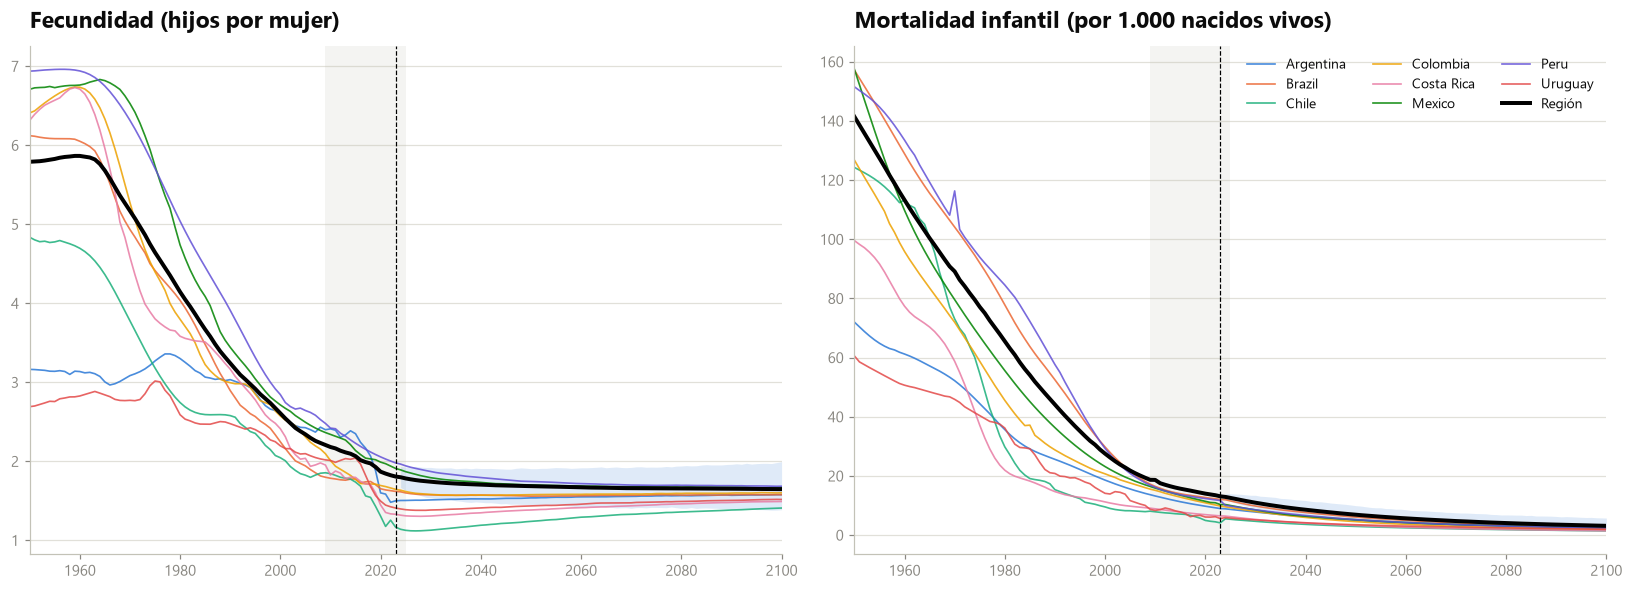

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
region = al.loc[al["ISO3_code"].eq("AL_REGION")]
for ax, ind, titulo in zip(axes, ["TFR", "IMR"], ["Fecundidad (hijos por mujer)", "Mortalidad infantil (por 1.000 nacidos vivos)"]):
    ax.axvspan(2009, 2025, color=GRIS, alpha=0.18, lw=0)
    for pais in PAISES:
        d = al.loc[al["Location"].eq(pais)]
        ax.plot(d["Time"], d[ind], color=COLOR[pais], lw=1.1, alpha=0.85, label=pais)
    ax.fill_between(region["Time"], region[f"{ind}_PI95_inf"], region[f"{ind}_PI95_sup"], color=DESTACADO, alpha=0.15, lw=0)
    ax.plot(region["Time"], region[ind], color="black", lw=2.6, label="Región")
    ax.axvline(ULTIMO_ESTIMADO, color="black", ls="--", lw=0.8)
    ax.set_title(titulo)
    ax.set_xlim(1950, 2100)
axes[1].legend(ncol=3, fontsize=9, loc="upper right")
plt.tight_layout()

In [3]:
# ¿Cuánto bajaron en la ventana de PISA?
d = al.loc[al["Time"].isin([2009, 2025]) & (al["en_panel_pisa"] | al["ISO3_code"].eq("AL_REGION"))]
cambio_demo = d.pivot_table(index="Location", columns="Time", values=["TFR", "IMR"]).round(2)
cambio_demo[("TFR", "cambio")] = (cambio_demo[("TFR", 2025)] - cambio_demo[("TFR", 2009)]).round(2)
cambio_demo[("IMR", "cambio_%")] = (100 * (cambio_demo[("IMR", 2025)] / cambio_demo[("IMR", 2009)] - 1)).round(0)
cambio_demo

IMR          TFR                   IMR
Time                              2009   2025  2009  2025 cambio cambio_%
Location                                                                 
Argentina                        13.66   8.70  2.40  1.50  -0.90    -36.0
Brazil                           17.24  11.57  1.80  1.60  -0.20    -33.0
Chile                             8.09   5.35  1.86  1.13  -0.73    -34.0
Colombia                         15.55   9.28  2.10  1.62  -0.48    -40.0
Costa Rica                        9.11   6.23  1.95  1.31  -0.64    -32.0
Latin America and the Caribbean  18.70  12.58  2.21  1.78  -0.43    -33.0
Mexico                           16.43  10.02  2.36  1.87  -0.49    -39.0
Peru                             16.87   9.81  2.48  1.94  -0.54    -42.0
Uruguay                           8.69   5.77  2.02  1.39  -0.63    -34.0

## 2. La parte educativa: desigualdad de aprendizaje en matemáticas

### Brecha P90 − P10

Puntos: la brecha en cada ciclo, con su intervalo aproximado del 95 % (± 1,96 errores estándar). El punto de 2006 (gris) es solo contexto. Argentina 2015 falta porque la OCDE lo considera no comparable.

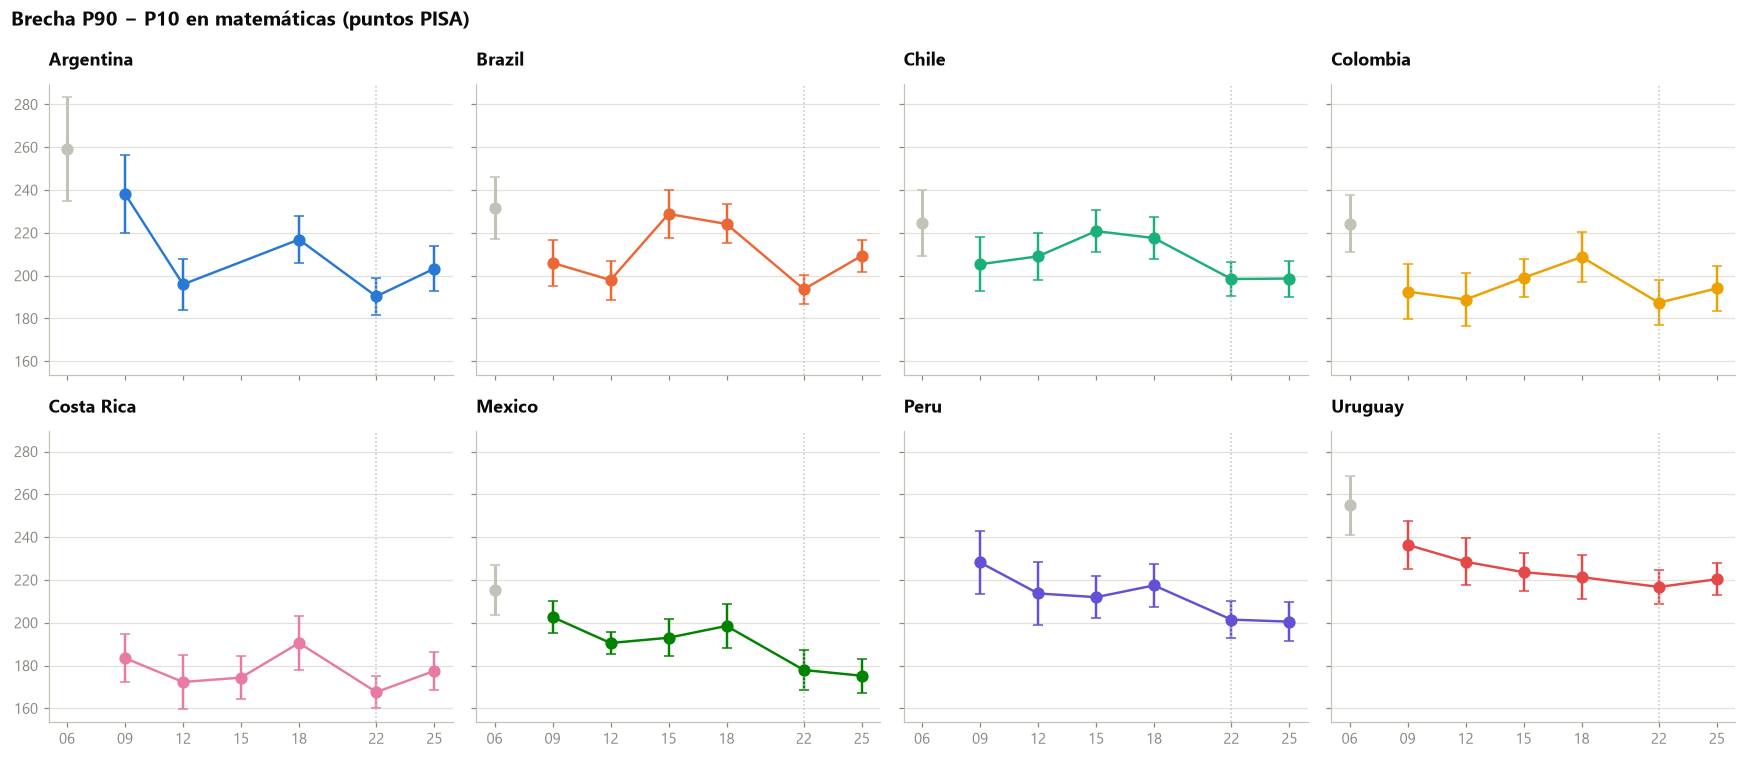

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True, sharex=True)
for ax, pais in zip(axes.flat, PAISES):
    d = mat.loc[mat["Pais"].eq(pais)].dropna(subset=["brecha_P90_P10"])
    principal = d.loc[d["en_panel_principal"]]
    ax.errorbar(principal["Time"], principal["brecha_P90_P10"], yerr=1.96 * principal["brecha_P90_P10_se"],
                color=COLOR[pais], marker="o", capsize=3, lw=1.6)
    ctx = d.loc[~d["en_panel_principal"]]
    ax.errorbar(ctx["Time"], ctx["brecha_P90_P10"], yerr=1.96 * ctx["brecha_P90_P10_se"], color=GRIS, marker="o", capsize=3, ls="none")
    ax.axvline(2022, color=GRIS, ls=":", lw=1)
    ax.set_title(pais, fontsize=12)
    ax.set_xticks(CICLOS_PANEL, [str(c)[2:] for c in CICLOS_PANEL])
fig.suptitle("Brecha P90 − P10 en matemáticas (puntos PISA)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

### % de estudiantes bajo el nivel 2

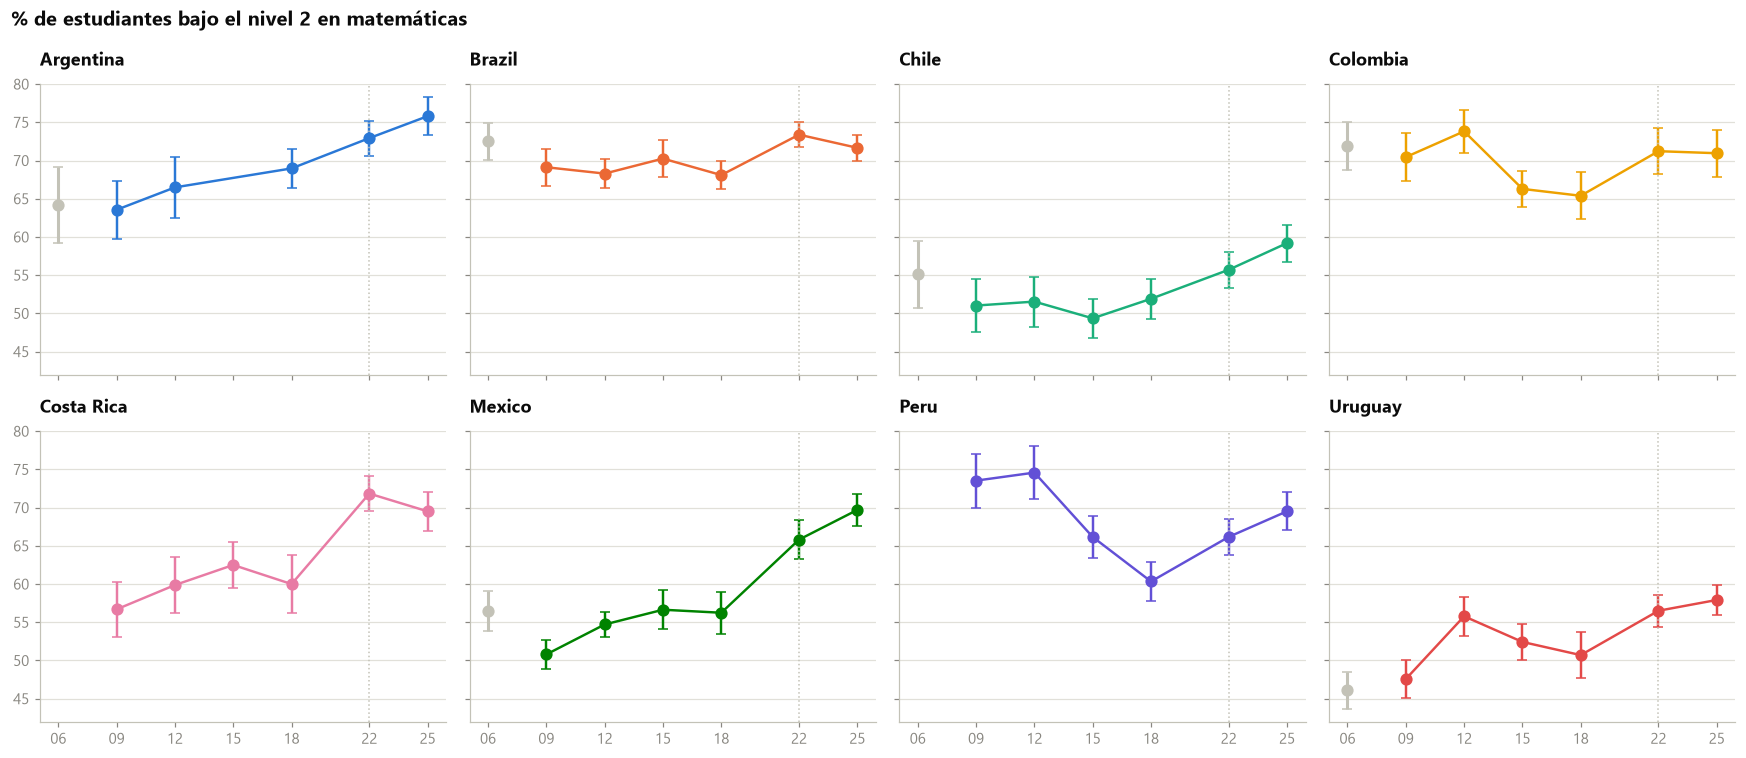

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True, sharex=True)
for ax, pais in zip(axes.flat, PAISES):
    d = mat.loc[mat["Pais"].eq(pais)].dropna(subset=["pct_bajo_nivel2"])
    principal = d.loc[d["en_panel_principal"]]
    ax.errorbar(principal["Time"], principal["pct_bajo_nivel2"], yerr=1.96 * principal["pct_bajo_nivel2_se"],
                color=COLOR[pais], marker="o", capsize=3, lw=1.6)
    ctx = d.loc[~d["en_panel_principal"]]
    ax.errorbar(ctx["Time"], ctx["pct_bajo_nivel2"], yerr=1.96 * ctx["pct_bajo_nivel2_se"], color=GRIS, marker="o", capsize=3, ls="none")
    ax.axvline(2022, color=GRIS, ls=":", lw=1)
    ax.set_title(pais, fontsize=12)
    ax.set_xticks(CICLOS_PANEL, [str(c)[2:] for c in CICLOS_PANEL])
fig.suptitle("% de estudiantes bajo el nivel 2 en matemáticas", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

### ¿Por qué cambia la brecha? Los dos extremos por separado

La brecha puede crecer porque los mejores mejoran o porque los más rezagados empeoran (y al revés). Mirar P10 y P90 por separado lo aclara.

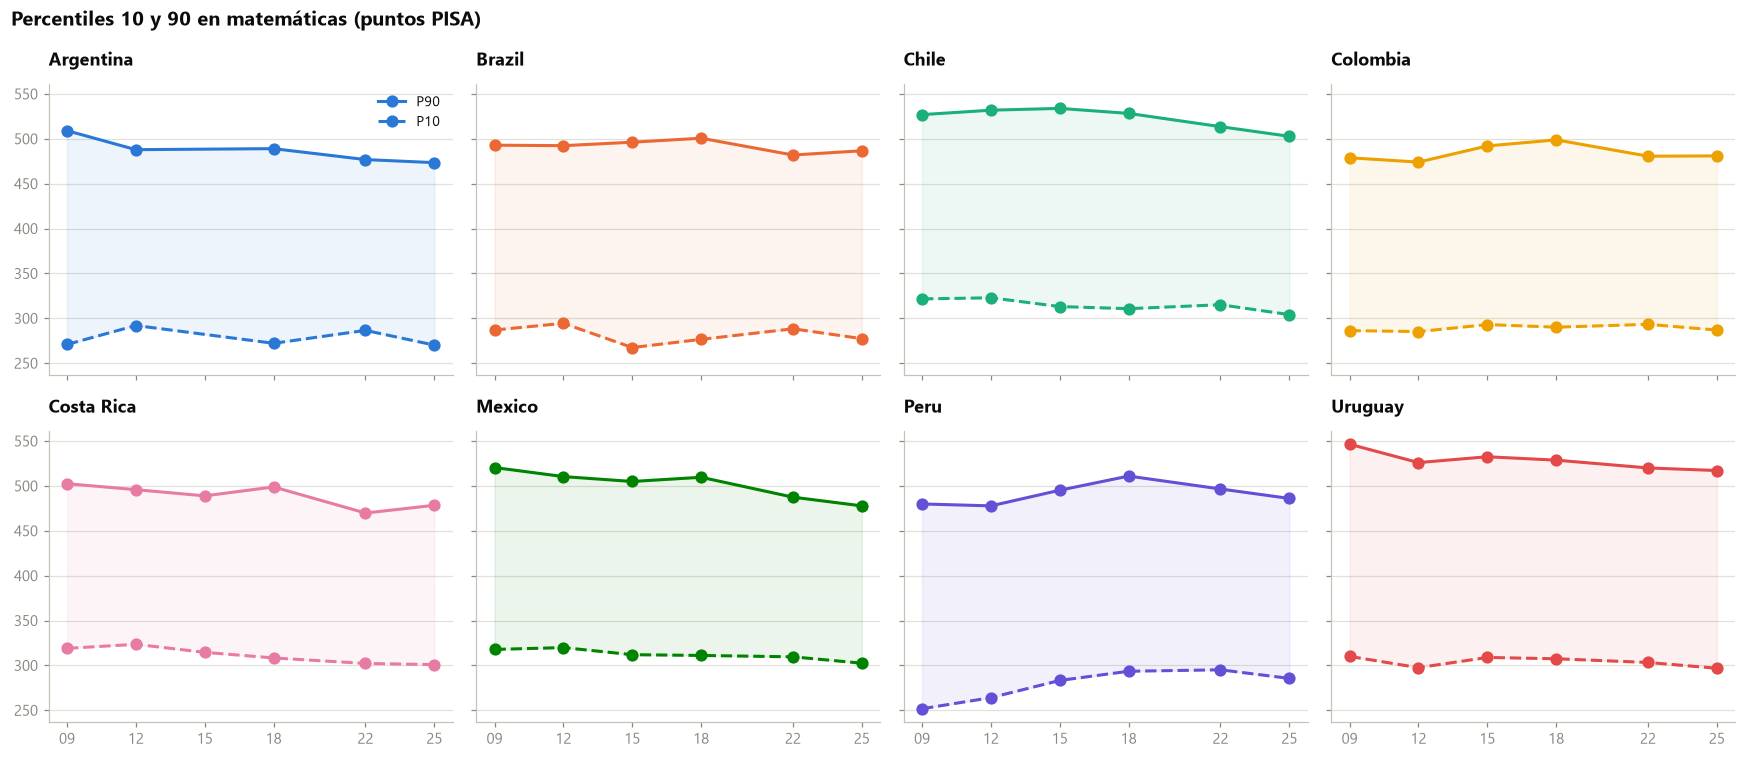

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True, sharex=True)
for ax, pais in zip(axes.flat, PAISES):
    d = mat.loc[mat["Pais"].eq(pais) & mat["en_panel_principal"]].dropna(subset=["P10"])
    ax.plot(d["Time"], d["P90"], marker="o", color=COLOR[pais], label="P90")
    ax.plot(d["Time"], d["P10"], marker="o", color=COLOR[pais], ls="--", label="P10")
    ax.fill_between(d["Time"], d["P10"], d["P90"], color=COLOR[pais], alpha=0.08)
    ax.set_title(pais, fontsize=12)
    ax.set_xticks(CICLOS_PANEL[1:], [str(c)[2:] for c in CICLOS_PANEL[1:]])
axes.flat[0].legend(fontsize=9)
fig.suptitle("Percentiles 10 y 90 en matemáticas (puntos PISA)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

## 3. Cobertura: cada vez más jóvenes de 15 años entran a la prueba

Índice de cobertura 3: proporción de todos los jóvenes de 15 años del país que representa PISA.

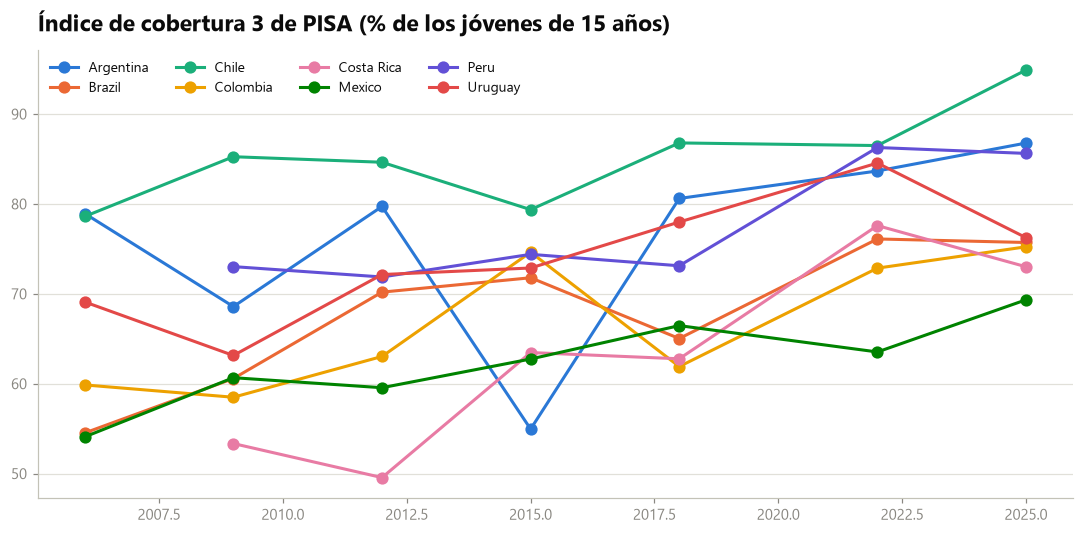

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
for pais in PAISES:
    d = mat.loc[mat["Pais"].eq(pais)].dropna(subset=["cobertura_ci3"])
    ax.plot(d["Time"], 100 * d["cobertura_ci3"], marker="o", color=COLOR[pais], label=pais)
ax.set_title("Índice de cobertura 3 de PISA (% de los jóvenes de 15 años)")
ax.legend(ncol=4, fontsize=9)
plt.tight_layout()

## 4. Cambios entre 2009 y 2025

Para cada país: cuánto cambió cada indicador entre el primer y el último ciclo del panel. Un cambio en la brecha se considera claro si supera 1,96 veces el error estándar de la diferencia (aproximación que trata los dos ciclos como muestras independientes).

In [8]:
def cambio(df, col):
    ini = df.loc[df["Time"].eq(2009)].set_index("Pais")
    fin = df.loc[df["Time"].eq(2025)].set_index("Pais")
    return fin[col] - ini[col], ini, fin

dif_b, ini, fin = cambio(mat, "brecha_P90_P10")
se_dif = np.sqrt(ini["brecha_P90_P10_se"] ** 2 + fin["brecha_P90_P10_se"] ** 2)

cambios = pd.DataFrame({
    "brecha_2009": ini["brecha_P90_P10"], "brecha_2025": fin["brecha_P90_P10"],
    "cambio_brecha": dif_b, "cambio_claro": (dif_b.abs() > 1.96 * se_dif).map({True: "sí", False: "no"}),
    "cambio_P10": fin["P10"] - ini["P10"], "cambio_P90": fin["P90"] - ini["P90"],
    "cambio_bajo_nivel2": fin["pct_bajo_nivel2"] - ini["pct_bajo_nivel2"],
    "cambio_TFR": fin["TFR"] - ini["TFR"], "cambio_IMR": fin["IMR"] - ini["IMR"],
    "cambio_cobertura_pp": 100 * (fin["cobertura_ci3"] - ini["cobertura_ci3"]),
}).sort_values("cambio_brecha")
cambios.round(2)

,brecha_2009,brecha_2025,cambio_brecha,cambio_claro,cambio_P10,cambio_P90,cambio_bajo_nivel2,cambio_TFR,cambio_IMR,cambio_cobertura_pp
Pais,,,,,,,,,,
Argentina,238.22,203.31,-34.91,sí,-0.73,-35.64,12.25,-0.90,-4.96,18.19
Peru,228.18,200.52,-27.67,sí,33.82,6.15,-4.01,-0.54,-7.07,12.59
Mexico,202.66,175.26,-27.40,sí,-15.32,-42.72,18.90,-0.50,-6.42,8.66
Uruguay,236.41,220.34,-16.06,sí,-13.25,-29.31,10.35,-0.63,-2.93,13.10
Chile,205.33,198.65,-6.67,no,-17.50,-24.18,8.17,-0.73,-2.74,9.64
Costa Rica,183.49,177.51,-5.97,no,-18.13,-24.10,12.82,-0.64,-2.88,19.66
Colombia,192.58,194.07,1.49,no,0.59,2.08,0.51,-0.48,-6.26,16.73
Brazil,205.98,209.34,3.35,no,-9.58,-6.23,2.54,-0.20,-5.67,15.13


In [9]:
print("Mediana de los 8 países:")
print(cambios.drop(columns="cambio_claro").median().round(2).to_string())

Mediana de los 8 países:
brecha_2009            205.66
brecha_2025            199.58
cambio_brecha          -11.37
cambio_P10             -11.41
cambio_P90             -24.14
cambio_bajo_nivel2       9.26
cambio_TFR              -0.58
cambio_IMR              -5.32
cambio_cobertura_pp     14.12


## 5. ¿Bajó más la desigualdad donde más bajaron la fecundidad y la mortalidad infantil?

Dispersión de los cambios 2009–2025, con la correlación de Spearman (por rangos, menos sensible a valores extremos). Con 8 países, una correlación tiene que ser muy fuerte para no ser fruto del azar: se reporta el valor p solo como referencia.

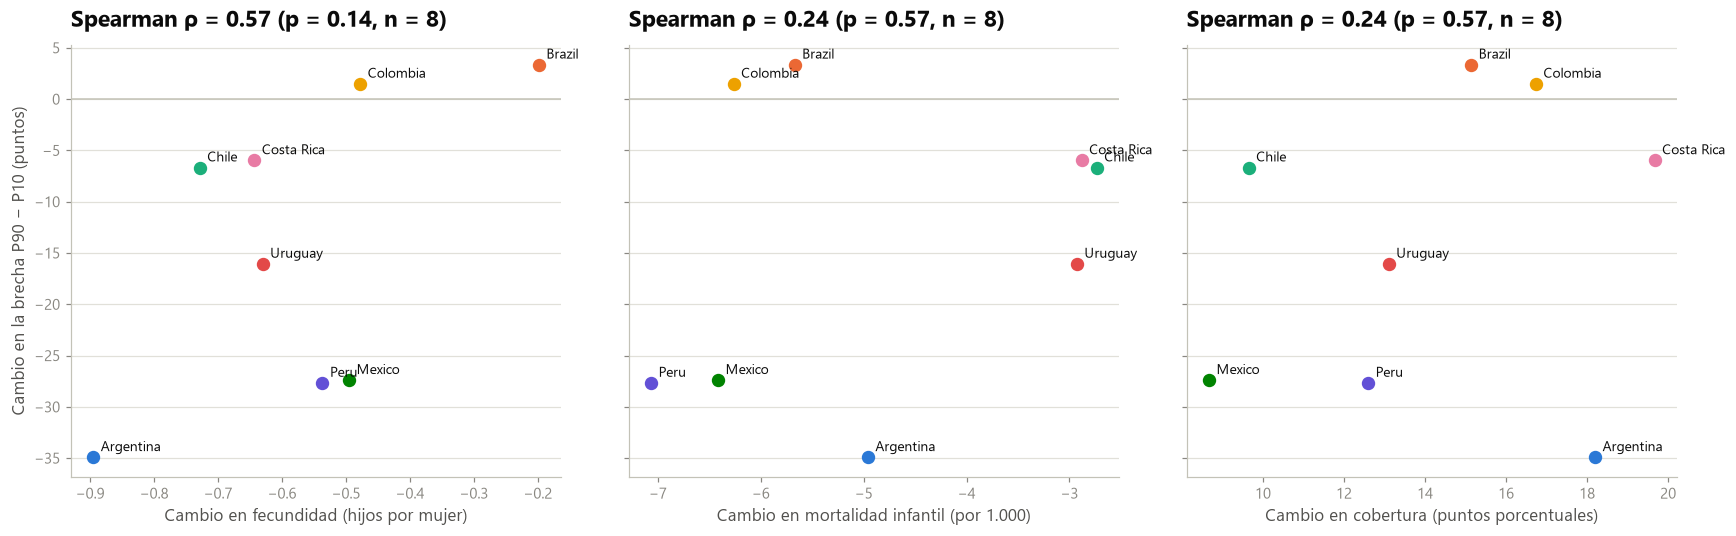

In [10]:
pares = [("cambio_TFR", "Cambio en fecundidad (hijos por mujer)"),
         ("cambio_IMR", "Cambio en mortalidad infantil (por 1.000)"),
         ("cambio_cobertura_pp", "Cambio en cobertura (puntos porcentuales)")]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, (col, etiqueta) in zip(axes, pares):
    for pais, fila in cambios.iterrows():
        ax.scatter(fila[col], fila["cambio_brecha"], color=COLOR[pais], s=60)
        ax.annotate(pais, (fila[col], fila["cambio_brecha"]), textcoords="offset points", xytext=(5, 4), fontsize=9)
    rho, p = stats.spearmanr(cambios[col], cambios["cambio_brecha"])
    ax.axhline(0, color=GRIS, lw=1)
    ax.set(xlabel=etiqueta, title=f"Spearman ρ = {rho:.2f} (p = {p:.2f}, n = 8)")
axes[0].set_ylabel("Cambio en la brecha P90 − P10 (puntos)")
plt.tight_layout()

## 6. Dentro de cada país, a lo largo de los ciclos

Usar solo 2009 y 2025 desperdicia los ciclos intermedios. Un modelo con **efectos fijos por país** compara cada país consigo mismo en el tiempo: responde «cuando la fecundidad de un país baja, ¿su brecha tiende a subir o a bajar?», sin mezclar las diferencias permanentes entre países.

- Modelo 1: brecha ~ fecundidad + país.
- Modelo 2: agrega la cobertura, para ver si la relación se explica porque entran más jóvenes a la prueba.
- Modelo 3: agrega una tendencia común en el tiempo, porque fecundidad y brecha podrían simplemente moverse con el calendario.

Errores estándar agrupados por país. Con solo 8 grupos son poco confiables: se leen como orientación, no como prueba.

In [11]:
datos = mat.loc[mat["en_panel_principal"]].dropna(subset=["brecha_P90_P10", "TFR", "cobertura_ci3"]).copy()
datos["cobertura_pp"] = 100 * datos["cobertura_ci3"]
modelos = {
    "1. TFR + país": "brecha_P90_P10 ~ TFR + C(Pais)",
    "2. + cobertura": "brecha_P90_P10 ~ TFR + cobertura_pp + C(Pais)",
    "3. + tendencia": "brecha_P90_P10 ~ TFR + cobertura_pp + Time + C(Pais)",
    "4. IMR + cobertura": "brecha_P90_P10 ~ IMR + cobertura_pp + C(Pais)",
}
filas = []
for nombre, f in modelos.items():
    m = smf.ols(f, data=datos).fit(cov_type="cluster", cov_kwds={"groups": datos["Pais"]})
    for var in ["TFR", "IMR", "cobertura_pp", "Time"]:
        if var in m.params:
            filas.append({"modelo": nombre, "variable": var, "coef": m.params[var], "ee_agrupado": m.bse[var],
                          "p": m.pvalues[var], "n": int(m.nobs)})
pd.DataFrame(filas).round(3)

,modelo,variable,coef,ee_agrupado,p,n
0,1. TFR + país,TFR,22.651,4.470,0.000,47
1,2. + cobertura,TFR,15.143,5.327,0.004,47
2,2. + cobertura,cobertura_pp,-0.374,0.302,0.216,47
3,3. + tendencia,TFR,23.378,9.634,0.015,47
4,3. + tendencia,cobertura_pp,-0.482,0.418,0.248,47
5,3. + tendencia,Time,0.491,0.697,0.481,47
6,4. IMR + cobertura,IMR,1.083,1.385,0.434,47
7,4. IMR + cobertura,cobertura_pp,-0.582,0.356,0.102,47


## 7. Robustez inicial

¿El patrón de la brecha se mantiene en lectura y ciencias, y si se quita 2022 (pandemia)? Para cada país se calcula la pendiente de la brecha por década (regresión simple sobre los ciclos 2009–2025), que usa todos los ciclos y no solo los extremos.

In [12]:
def pendiente_decada(d):
    d = d.dropna(subset=["brecha_P90_P10"])
    return 10 * np.polyfit(d["Time"], d["brecha_P90_P10"], 1)[0] if len(d) >= 3 else np.nan

base = panel.loc[panel["en_panel_principal"]]
rob = pd.DataFrame({
    materia: base.loc[base["Materia"].eq(materia)].groupby("Pais").apply(pendiente_decada, include_groups=False)
    for materia in ["Matematicas", "Lectura", "Ciencias"]
})
rob["Matematicas_sin_2022"] = base.loc[base["Materia"].eq("Matematicas") & base["Time"].ne(2022)].groupby("Pais").apply(pendiente_decada, include_groups=False)
rob.loc["Mediana"] = rob.median()
print("Pendiente de la brecha P90 − P10, puntos por década (positivo = la desigualdad crece):")
rob.round(1)

Pendiente de la brecha P90 − P10, puntos por década (positivo = la desigualdad crece):


,Matematicas,Lectura,Ciencias,Matematicas_sin_2022
Pais,,,,
Argentina,-16.7,-20.3,-9.6,-12.5
Brazil,-1.0,14.2,23.4,5.5
Chile,-6.7,23.9,15.4,-4.0
Colombia,0.6,13.6,19.3,3.9
Costa Rica,-2.8,15.5,14.4,0.7
Mexico,-15.3,-0.6,1.8,-13.8
Peru,-15.1,-12.7,-1.8,-13.9
Uruguay,-10.3,2.1,-9.4,-9.3
Mediana,-8.5,7.8,8.1,-6.7


In [13]:
signos = (rob.drop(index="Mediana") > 0).sum()
print("Países (de 8) donde la brecha crece, por versión:")
print(signos.to_string())

Países (de 8) donde la brecha crece, por versión:
Matematicas             1
Lectura                 5
Ciencias                5
Matematicas_sin_2022    3


## 8. Hallazgos preliminares → tareas para el análisis del miércoles

Lo que muestran las salidas de arriba (exploratorio, 8 países):

1. **La demografía cambió en la misma dirección en los 8 países.** Entre 2009 y 2025 la fecundidad bajó entre 0,2 hijos por mujer (Brasil) y 0,9 (Argentina), y la mortalidad infantil cayó entre un 32 % y un 42 %. La cobertura de PISA subió entre 9 y 20 puntos porcentuales en todos.
2. **En matemáticas, la brecha P90 − P10 se redujo en 6 de 8 países** (con claridad en Argentina, Perú, México y Uruguay); mediana: −11 puntos.
3. **Pero se cerró sobre todo «hacia abajo».** En la mediana, el percentil 90 cayó 24 puntos y el 10 cayó 11: la brecha se achicó porque los mejores retrocedieron más que los rezagados. El % bajo el nivel 2 **subió en 7 de 8 países** (mediana: +9 puntos porcentuales).
4. **Perú es la excepción: se cerró «hacia arriba».** Su percentil 10 subió 34 puntos y el % bajo el nivel 2 bajó 4 puntos.
5. **El resultado no se repite en otras materias.** En lectura y ciencias la brecha creció en 5 de 8 países (mediana: unos +8 puntos por década). Sin el ciclo 2022, en matemáticas crece en 3 de 8.
6. **La relación con la demografía es débil y solo aparece en matemáticas.** Entre países, los que más redujeron su fecundidad tendieron a reducir más la brecha (Spearman ρ = 0,57; p = 0,14). Dentro de cada país, los ciclos con más fecundidad tienen brechas mayores (unos 15 a 23 puntos por hijo, estable al controlar cobertura y tendencia). Con la mortalidad infantil no hay relación clara. Con 8 países, todo esto es orientativo.
7. **La cobertura complica la lectura.** Hoy entran a PISA jóvenes que antes no llegaban a los 15 años en el colegio. Parte del aumento del % bajo el nivel 2 puede reflejar esa inclusión, no un deterioro del sistema.

**Tareas para el miércoles:**

- Decidir el eje de la historia: «la brecha se cerró, pero hacia abajo» con Perú como contraejemplo.
- Robustez formal: el mismo modelo de efectos fijos en lectura y ciencias; quitar un país a la vez; considerar el error de enlace en los cambios del % bajo el nivel 2.
- Probar la fecundidad y la mortalidad infantil **al nacer** de los evaluados (ciclo − 15) como alternativa.
- Contexto de cierre: qué proyecta la ONU para la región hasta 2050, con su incertidumbre.
- De 4 a 6 figuras finales en inglés en `03_visualizaciones`.